# 12 — Projet final : tri de composants et détection d'anomalies

Ce notebook réunit tout le cours dans un scénario industriel réaliste :

1. une caméra filme des composants sur un convoyeur et un modèle doit les
   classer (résistance, condensateur, diode) ;
2. un capteur de courant surveille une machine et doit signaler les
   comportements anormaux sans qu'on lui ait fourni d'étiquettes.

**Objectifs du notebook**

- fabriquer un jeu d'images synthétiques pour entraîner un modèle ;
- entraîner un réseau convolutif (CNN) avec PyTorch ;
- évaluer un classifieur avec une matrice de confusion ;
- détecter des anomalies non supervisées avec IsolationForest ;
- sauvegarder les modèles et écrire une fonction d'inférence réutilisable.

**Prérequis** : notebooks 10 et 11.


## Utilisation en ligne (Google Colab)

Cette cellule ne fait rien sur votre ordinateur. Dans Google Colab, elle
clone le dépôt public (données comprises) et place le notebook à sa racine,
afin que les chemins `data/...` fonctionnent. Exécutez-la en premier.


In [1]:
import os  # manipulation des chemins et du dossier courant
import subprocess  # lance la commande git clone
import sys  # permet de détecter l'environnement Colab

DEPOT = "https://github.com/VladdKid/python-electronique-ia.git"  # adresse publique du cours
DOSSIER = "python-electronique-ia"  # dossier local créé par le clone

if "google.colab" in sys.modules and not os.path.isdir("data"):  # uniquement dans Colab, si les données manquent
    if not os.path.isdir(DOSSIER):  # évite de cloner deux fois le dépôt
        subprocess.run(["git", "clone", "--depth", "1", DEPOT, DOSSIER], check=True)  # télécharge le cours
    os.chdir(DOSSIER)  # se place à la racine du dépôt cloné
    print(f"Dépôt prêt : {os.getcwd()}")  # confirme le dossier de travail


## Partie A — Fabriquer un jeu de données d'images

Un CNN a besoin de nombreuses images. En attendant de photographier de vrais
composants, on dessine des images 32 × 32 en niveaux de gris avec NumPy :
fond bruité, pattes de connexion, corps spécifique à chaque composant.
Les images sont ensuite légèrement tournées pour simuler la position
aléatoire des pièces sur le tapis.


In [2]:
import json  # sauvegarde des noms de classes
import numpy as np  # génération des images
import matplotlib.pyplot as plt  # affichage
import torch  # réseaux de neurones
from torch import nn  # couches du réseau
from scipy import ndimage  # rotation des images
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report  # évaluation


In [3]:
def fond(rng):  # fabrique un fond gris bruité, comme un convoyeur éclairé irrégulièrement
    return rng.normal(0.0, 0.03, (32, 32))  # matrice 32 × 32 de bruit faible

def image_resistance(rng):  # dessine une résistance : corps rectangulaire et trois bandes
    img = fond(rng)  # part d'un fond bruité
    y0 = 16 + rng.integers(-2, 3)  # ligne du corps, avec un décalage aléatoire de ±2 pixels
    x0 = 16 + rng.integers(-2, 3)  # colonne centrale, également décalée
    demi_longueur = rng.integers(8, 10)  # demi-longueur du corps : 8 ou 9 pixels
    demi_hauteur = rng.integers(3, 5)  # demi-hauteur du corps : 3 ou 4 pixels
    img[y0, :] = 0.75  # trace la patte de connexion sur toute la largeur
    img[y0 - demi_hauteur:y0 + demi_hauteur, x0 - demi_longueur:x0 + demi_longueur] = 0.88  # corps clair
    for decalage in (-4, 0, 4):  # trois bandes de couleur à des positions fixes
        img[y0 - demi_hauteur:y0 + demi_hauteur, x0 + decalage:x0 + decalage + 1] = 0.25  # bande sombre
    return np.clip(img, 0.0, 1.0)  # borne les valeurs entre noir et blanc

def image_condensateur(rng):  # dessine un condensateur : deux plaques parallèles
    img = fond(rng)  # fond bruité
    y0 = 16 + rng.integers(-2, 3)  # position verticale aléatoire
    x0 = 16 + rng.integers(-2, 3)  # position horizontale aléatoire
    img[y0, :x0 - 3] = 0.75  # patte gauche
    img[y0, x0 + 3:] = 0.75  # patte droite
    img[y0 - 6:y0 + 6, x0 - 3:x0 - 1] = 0.9  # plaque gauche (2 pixels d'épaisseur)
    img[y0 - 6:y0 + 6, x0 + 1:x0 + 3] = 0.9  # plaque droite, séparée par un vide
    return np.clip(img, 0.0, 1.0)  # borne les valeurs

def image_diode(rng):  # dessine une diode : triangle et barre
    img = fond(rng)  # fond bruité
    y0 = 16 + rng.integers(-2, 3)  # position verticale aléatoire
    x0 = 14 + rng.integers(-2, 3)  # position horizontale du triangle
    img[y0, :x0] = 0.75  # patte gauche
    img[y0, x0 + 9:] = 0.75  # patte droite
    for dx in range(8):  # construit le triangle colonne par colonne
        demi = int(round(4 * (1 - dx / 8)))  # hauteur du triangle décroît vers la pointe
        img[y0 - demi:y0 + demi + 1, x0 + dx] = 0.9  # remplit la colonne correspondante
    img[y0 - 4:y0 + 5, x0 + 9:x0 + 11] = 0.9  # barre verticale de la cathode
    return np.clip(img, 0.0, 1.0)  # borne les valeurs


On génère 240 images par classe, soit 720 au total. Chaque image subit une
rotation aléatoire de ±25° : le modèle apprend ainsi à reconnaître un
composant quelle que soit son orientation sur le convoyeur.


In [4]:
rng = np.random.default_rng(2026)  # générateur reproductible
classes = ["résistance", "condensateur", "diode"]  # noms des trois classes
generateurs = [image_resistance, image_condensateur, image_diode]  # une fonction par classe
images = []  # future liste d'images
etiquettes = []  # future liste d'étiquettes numériques

for numero, generateur in enumerate(generateurs):  # parcourt les trois classes
    for _ in range(240):  # 240 exemplaires par classe
        image = generateur(rng)  # dessine un composant
        image = ndimage.rotate(image, rng.uniform(-25.0, 25.0), reshape=False, order=1)  # rotation aléatoire
        images.append(np.clip(image, 0.0, 1.0))  # stocke l'image normalisée
        etiquettes.append(numero)  # stocke la classe (0, 1 ou 2)

images = np.array(images, dtype="float32")[:, None, :, :]  # forme (720, 1, 32, 32) : canal unique
etiquettes = np.array(etiquettes, dtype="int64")  # forme (720,)
print(images.shape, etiquettes.shape)  # vérifie les dimensions


(720, 1, 32, 32) (720,)


`images[:, None, :, :]` ajoute un axe « canal » : PyTorch attend
`(lot, canaux, hauteur, largeur)`. Nos images étant en niveaux de gris, il
n'y a qu'un seul canal.


In [5]:
indices = rng.permutation(len(images))  # mélange les indices pour éviter un ordre par classe
images = images[indices]  # applique le mélange aux images
etiquettes = etiquettes[indices]  # applique le même mélange aux étiquettes

nb_train = int(0.8 * len(images))  # 80 % pour l'apprentissage
X_train = torch.tensor(images[:nb_train])  # images d'apprentissage
y_train = torch.tensor(etiquettes[:nb_train])  # étiquettes d'apprentissage
X_test = torch.tensor(images[nb_train:])  # 20 % pour le test
y_test = torch.tensor(etiquettes[nb_train:])  # étiquettes de test
print(f"Apprentissage : {len(X_train)} images | Test : {len(X_test)} images")  # 576 et 144


Apprentissage : 576 images | Test : 144 images


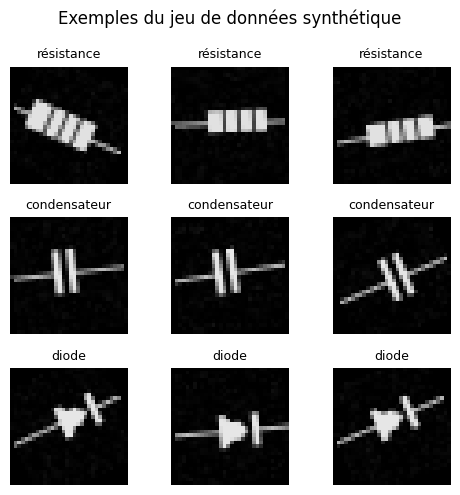

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(5.0, 5.0))  # grille de 9 vignettes
for classe in range(3):  # une ligne par classe
    exemples = np.flatnonzero(etiquettes == classe)[:3]  # trois indices de cette classe
    for colonne, index in enumerate(exemples):  # trois vignettes par ligne
        axes[classe, colonne].imshow(images[index, 0], cmap="gray", vmin=0.0, vmax=1.0)  # affiche l'image
        axes[classe, colonne].set_title(classes[classe], fontsize=9)  # titre = nom de la classe
        axes[classe, colonne].axis("off")  # masque les graduations
fig.suptitle("Exemples du jeu de données synthétique")  # titre général
fig.tight_layout()  # ajuste les marges
plt.show()  # affiche


## Partie B — Entraîner un réseau convolutif

Un CNN alterne **convolutions** (détection de motifs locaux : bords, coins,
formes) et **regroupements** (`MaxPool2d`, qui réduit la résolution). Les
couches finales `Linear` prennent la décision. C'est le même schéma que pour
reconnaître des chiffres ou des défauts de soudure sur une carte.


In [7]:
torch.manual_seed(42)  # initialisation reproductible
modele_cnn = nn.Sequential(  # réseau convolutif simple
    nn.Conv2d(1, 8, kernel_size=3, padding=1),  # 1 canal → 8 cartes de caractéristiques, noyau 3 × 3
    nn.ReLU(),  # non-linéarité
    nn.MaxPool2d(2),  # divise la taille par 2 : 32 × 32 → 16 × 16
    nn.Conv2d(8, 16, kernel_size=3, padding=1),  # 8 → 16 cartes, toujours en 16 × 16
    nn.ReLU(),  # non-linéarité
    nn.MaxPool2d(2),  # 16 × 16 → 8 × 8
    nn.Flatten(),  # met les 16 × 8 × 8 = 1024 valeurs à plat
    nn.Linear(16 * 8 * 8, 32),  # couche dense de réduction
    nn.ReLU(),  # non-linéarité
    nn.Linear(32, 3),  # trois scores de sortie, un par classe
)
optimiseur_cnn = torch.optim.Adam(modele_cnn.parameters(), lr=0.001)  # optimiseur Adam
perte_cnn = nn.CrossEntropyLoss()  # perte de classification à 3 classes
print(sum(p.numel() for p in modele_cnn.parameters()), "paramètres à entraîner")  # taille du modèle


34147 paramètres à entraîner


In [8]:
jeu_train = torch.utils.data.TensorDataset(X_train, y_train)  # associe images et étiquettes
chargeur_train = torch.utils.data.DataLoader(jeu_train, batch_size=32, shuffle=True)  # lots de 32 images mélangées

for epoque in range(3):  # trois passages suffisent pour ce jeu simple
    modele_cnn.train()  # mode apprentissage
    perte_cumulee = 0.0  # perte cumulée sur l'époque
    for x_lot, y_lot in chargeur_train:  # parcourt les lots
        optimiseur_cnn.zero_grad()  # efface les gradients précédents
        sorties = modele_cnn(x_lot)  # passe avant du CNN
        perte = perte_cnn(sorties, y_lot)  # calcule la perte du lot
        perte.backward()  # rétropropagation
        optimiseur_cnn.step()  # mise à jour des poids
        perte_cumulee += perte.item() * len(x_lot)  # accumule la perte pondérée
    modele_cnn.eval()  # passe en mode évaluation
    with torch.no_grad():  # pas de gradient pour l'évaluation
        predictions_train = modele_cnn(X_train).argmax(dim=1)  # prédictions sur l'apprentissage
    precision_train = accuracy_score(y_train.numpy(), predictions_train.numpy())  # précision d'apprentissage
    print(f"époque {epoque} | perte {perte_cumulee / len(X_train):.4f} | précision train {precision_train * 100:.1f} %")  # suivi


époque 0 | perte 1.0629 | précision train 69.1 %


époque 1 | perte 0.8499 | précision train 89.6 %


époque 2 | perte 0.4211 | précision train 98.6 %


In [9]:
modele_cnn.eval()  # mode évaluation
with torch.no_grad():  # pas de calcul de gradient
    scores_test = modele_cnn(X_test)  # scores du modèle sur les images de test
    predictions_test = scores_test.argmax(dim=1).numpy()  # classe la plus probable
print(f"Précision sur le test : {accuracy_score(y_test.numpy(), predictions_test) * 100:.1f} %")  # performance réelle


Précision sur le test : 97.9 %


In [10]:
matrice = confusion_matrix(y_test.numpy(), predictions_test)  # matrice 3 × 3
print(matrice)  # lignes = vérité, colonnes = prédiction
print(classification_report(y_test.numpy(), predictions_test, target_names=classes))  # précision et rappel par classe


[[45  0  0]
 [ 0 41  2]
 [ 0  1 55]]
              precision    recall  f1-score   support

  résistance       1.00      1.00      1.00        45
condensateur       0.98      0.95      0.96        43
       diode       0.96      0.98      0.97        56

    accuracy                           0.98       144
   macro avg       0.98      0.98      0.98       144
weighted avg       0.98      0.98      0.98       144



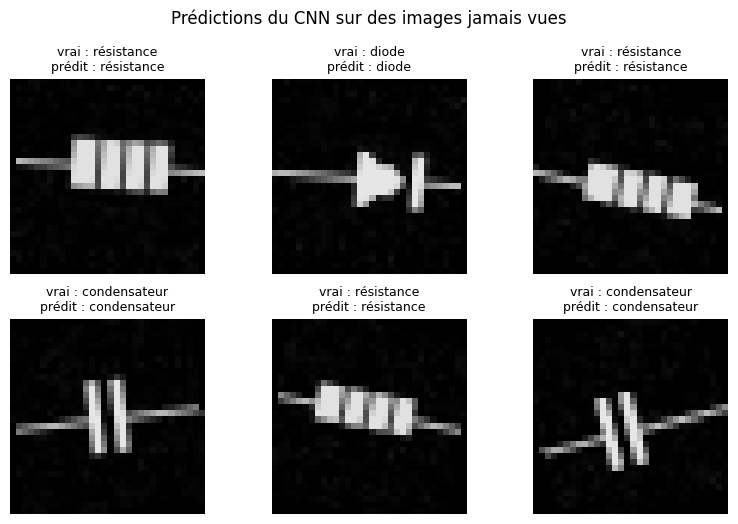

In [11]:
exemples = np.arange(6)  # six images de test à inspecter
fig, axes = plt.subplots(2, 3, figsize=(8.0, 5.3))  # grille 2 × 3
for ax, index in zip(axes.ravel(), exemples):  # parcourt la grille et les indices
    ax.imshow(X_test[index, 0], cmap="gray", vmin=0.0, vmax=1.0)  # affiche l'image
    vraie = classes[int(y_test[index])]  # classe réelle
    predite = classes[int(predictions_test[index])]  # classe prédite
    ax.set_title(f"vrai : {vraie}\nprédit : {predite}", fontsize=9)  # compare les deux
    ax.axis("off")  # masque les axes
fig.suptitle("Prédictions du CNN sur des images jamais vues")  # titre
fig.tight_layout()  # marges
plt.show()  # affiche


Le modèle atteint environ 98 % de précision en quelques secondes. Cette
performance élevée vient de la simplicité du jeu synthétique. Avec de vraies
photos (reflets, saleté, éclairage variable), il faudrait des milliers
d'images et de la **data augmentation**.


## Partie C — Détecter des anomalies sans étiquettes

Sur une machine, les pannes sont rares : on n'a pas assez d'exemples de
défauts pour un apprentissage supervisé. **IsolationForest** apprend la forme
des données normales, puis signale les points faciles à isoler, donc rares ou
extrêmes. C'est un modèle **non supervisé** : il n'utilise jamais la colonne
`defaut` pour s'entraîner.


In [12]:
import pandas as pd  # lecture des mesures
from sklearn.ensemble import IsolationForest  # détecteur d'anomalies
import joblib  # sauvegarde de modèles scikit-learn

mesures = pd.read_csv("data/mesures_capteur.csv", parse_dates=["horodatage"])  # charge le journal du capteur
print(mesures.shape)  # 1800 mesures
print(f"Courant moyen : {mesures['courant_mA'].mean():.2f} mA")  # le pic à 60 mA doit ressortir


(1800, 5)
Courant moyen : 12.13 mA


In [13]:
detecteur = IsolationForest(  # crée le détecteur
    contamination=0.01,  # on s'attend à environ 1 % de mesures anormales
    n_estimators=200,  # 200 arbres : plus stable qu'une forêt de 10 arbres
    random_state=42,  # reproductibilité
)
detecteur.fit(mesures[["courant_mA"]].to_numpy())  # apprend la distribution du courant (une seule variable)
anomalies = detecteur.predict(mesures[["courant_mA"]].to_numpy()) == -1  # -1 = anomalie, 1 = normal
print(f"{anomalies.sum()} mesures signalées comme anormales")  # environ 16 sur 1800


16 mesures signalées comme anormales


In [14]:
reels = mesures["courant_mA"] > 40.0  # vérité terrain approximative : pics au-delà de 40 mA
vrais_positifs = (anomalies & reels).sum()  # anomalies détectées qui sont de vrais pics
precision = vrais_positifs / anomalies.sum()  # parmi les alertes, part de vraies anomalies
rappel = vrais_positifs / reels.sum()  # parmi les vrais pics, part détectée
print(f"Pics réels : {reels.sum()} | détectés : {vrais_positifs}")  # 6 pics au total
print(f"Précision : {precision * 100:.0f} % | Rappel : {rappel * 100:.0f} %")  # rappel 100 %, précision plus faible


Pics réels : 6 | détectés : 6
Précision : 38 % | Rappel : 100 %


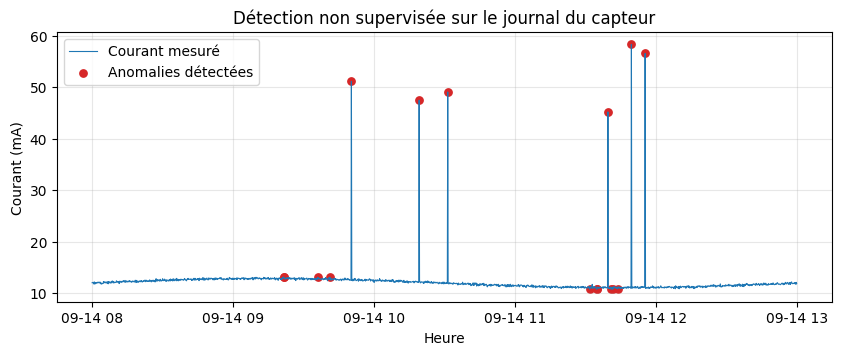

In [15]:
fig, ax = plt.subplots(figsize=(10.0, 3.5))  # grande figure pour la série temporelle
ax.plot(mesures["horodatage"], mesures["courant_mA"], linewidth=0.8, label="Courant mesuré")  # courbe brute
ax.scatter(mesures.loc[anomalies, "horodatage"], mesures.loc[anomalies, "courant_mA"], color="tab:red", s=28, label="Anomalies détectées")  # points rouges
ax.set_xlabel("Heure")  # axe horizontal
ax.set_ylabel("Courant (mA)")  # axe vertical
ax.set_title("Détection non supervisée sur le journal du capteur")  # titre
ax.legend()  # légende
ax.grid(True, alpha=0.3)  # grille
plt.show()  # affiche


**Lecture du résultat** : le rappel est de 100 % (aucun pic manqué) mais la
précision est faible (beaucoup de fausses alertes). En production, on règle
`contamination` et on ajoute des variables (tension, température) pour
réduire les fausses alertes. Le coût d'un défaut manqué est souvent bien
supérieur à celui d'une vérification inutile : le réglage est un choix métier.


## Partie D — Sauvegarder et réutiliser les modèles

Un modèle n'a de valeur que s'il peut être déployé. On sauvegarde les poids
du CNN, la liste des classes, puis la forêt d'isolation. La fonction
d'inférence ci-dessous prend une image NumPy et renvoie une étiquette : c'est
exactement ce qu'on appellerait depuis une caméra sur un Raspberry Pi.


In [16]:
torch.save(modele_cnn.state_dict(), "models/trieur_composants.pt")  # poids du CNN
with open("models/classes_composants.json", "w", encoding="utf-8") as fichier:  # fichier des noms de classes
    json.dump(classes, fichier, ensure_ascii=False)  # écrit ["résistance", "condensateur", "diode"]
joblib.dump(detecteur, "models/detecteur_anomalies.joblib")  # sauvegarde du détecteur
print("Modèles enregistrés dans models/")  # confirmation


Modèles enregistrés dans models/


In [17]:
def predire_composant(image):  # inférence : une image 32 × 32 → un nom de composant
    tenseur = torch.tensor(image[None, None, :, :], dtype=torch.float32)  # ajoute les axes lot et canal
    modele_cnn.eval()  # mode évaluation
    with torch.no_grad():  # pas de gradient
        classe = modele_cnn(tenseur).argmax(dim=1).item()  # indice de la classe la plus probable
    return classes[classe]  # renvoie le nom lisible

exemple = images[nb_train, 0]  # une image 32 × 32 du jeu de test, sans l'axe du canal
print(f"Prédiction : {predire_composant(exemple)} | Vérité : {classes[int(etiquettes[nb_train])]}")  # compare


Prédiction : résistance | Vérité : résistance


In [18]:
detecteur_recharge = joblib.load("models/detecteur_anomalies.joblib")  # recharge le détecteur
courant_test = np.array([[55.0]])  # une mesure de courant anormale
etat = detecteur_recharge.predict(courant_test)[0]  # -1 = anomalie
print("ALARME" if etat == -1 else "Normal")  # affiche le verdict


ALARME


**Pour aller vers un vrai déploiement** : convertir le CNN en TorchScript ou
en ONNX, l'exécuter sur une carte embarquée, envoyer les alertes par MQTT, et
surveiller la dérive du modèle (les composants ou l'éclairage changent avec
le temps). La démarche reste la même : données → modèle → évaluation →
déploiement → surveillance.


## À vous de jouer

**Exercice 1** — Ajoutez une quatrième classe « transistor » : un petit
rectangle avec trois pattes. Générez 240 images, ajoutez le nom dans
`classes`, remplacez la dernière couche par `nn.Linear(32, 4)` et
réentraînez. La précision reste-t-elle bonne ?


In [19]:
# TODO : écrivez une fonction image_transistor(rng)

# TODO : régénérez les images avec 4 classes

# TODO : adaptez le CNN (dernière couche à 4 sorties) et réentraînez


**Exercice 2** — Réduisez le jeu à 60 images par classe (au lieu de 240).
Comparez la précision de test. Que se passe-t-il : surapprentissage ou
sous-apprentissage ?


In [20]:
# TODO : régénérez un jeu réduit avec 60 images par classe

# TODO : réentraînez le même CNN et affichez la précision train et test


**Exercice 3** — Testez `contamination=0.005` puis `contamination=0.02`.
Pour chaque valeur, calculez le nombre d'alertes et le rappel. Quel réglage
choisiriez-vous pour une machine critique ? Justifiez.


In [21]:
# TODO : bouclez sur [0.005, 0.01, 0.02]

# TODO : pour chaque valeur, affichez alertes, vrais positifs et rappel


## À retenir

- Un CNN enchaîne convolution → activation → regroupement, puis des couches denses.
- Un jeu d'images peut être fabriqué et augmenté pour démarrer un projet.
- Une matrice de confusion révèle les confusions entre classes ; l'exactitude seule ne suffit pas.
- IsolationForest détecte des anomalies sans étiquettes, au prix de fausses alertes.
- `state_dict`, JSON et joblib permettent de déployer les modèles.

**Et après ?** Approfondissez : CNN pré-entraînés (transfer learning),
séries temporelles (LSTM), quantification pour l'embarqué, et toujours :
mesurer, comparer, documenter.
